# calculating velocity using new definition of $n_{\rm crit}$

In [1]:
import numpy as np
import time
import tqdm as tqdm
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import fsolve, approx_fprime, root_scalar, root, least_squares
from numdifftools import Gradient, Derivative
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFsolve_mu, RMFpressureSYM, RMFpressurePNM, pressure_RMF
from RMFsolver.phase_velocity import * #P_f, vNtoQ_Pc, vNtoQ_B, vNtoQ_nc, PQM, Get_Two_as_dens, Get_Two_as_pres
from RMFsolver.phase_velocity import _find_muB_muK_star, _vNtoQ_formula, _vNtoQ_num

n0 = 0.16 * const.MeV_fm**3

In [2]:
# Taking transition density, strange quark mass, NM model name as input
#def vNtoQ_fixB(T, n_crit, Deln, m_s, param, NM_type, method="analytical", aQmax=True):
'''
Computes NM to SQM phase boundary velocity 

Parameters:
- T        : temperature
- n_crit   : critical density for 1st order phase transition at T=0
- Deln     : Messures how far away from equilibrium
- m_s      : strange quark mass
- param    : mean field theory model settings for nuclear matter
- NM_type  : assumptions for nuclear matter, choose from:
             - "Beta_eq" for beta equilibriated nuclear matter
             - "PNM" for pure neutron matter
             - "SYM" for symmetric nuclear matter
- method   : ways to calculate velocity
             - "numerical" in principle more precise, but have numerical noise
             - "analytical" analytical approximation, direct, faster, and robust, ~ 10% difference with numerical method
- aQmax    : whether not to use analytical approximation for calculating aQmax
             - Default: True

Returns:
- velocity of phase boundary in meters per second
'''

def PNM(mu_B, Temp):
    if NM_type == "Beta_eq":
        rmf_sol = RMFsolve_mu(mub = mu_B, Trmf = Temp, para = param, 
            sigma_init = 30, w0_init = 20, r03_init = -3, mu_e_init = 50, verb = False
            )
        return (pressure_RMF(rmf_sol)).item()

    elif NM_type == "PNM":
        pre = RMFpressurePNM(input_num = mu_B, input_type = "muB", Trmf = Temp, para = param, 
            sigma_init = 30, w0_init = 20, r03_init = -3, mub_init = 990, verb = False
            )
        return float(pre.item())

    elif NM_type == "SYM":
        pre = RMFpressureSYM(input_num = mu_B, input_type = "muB", Trmf = Temp, para = param, 
            sigma_init = 30, w0_init = 20, mub_init = 990, verb = False
            )
        return float(pre.item())

    else:
        return ValueError("Nuclear matter type not defined.")


def PNM_n(nB, Temp):
    if NM_type == "Beta_eq":
        rmf_sol = RMFsolve(nbext = nB, Trmf = Temp, para = param, 
            sigma_init = 30, w0_init = 20, r03_init = -3, mu_e_init = 50, verb = False
            )
        return (pressure_RMF(rmf_sol)).item()

    elif NM_type == "PNM":
        pre = RMFpressurePNM(input_num = nB, input_type = "nB", Trmf = Temp, para = param, 
            sigma_init = 30, w0_init = 20, r03_init = -3, mub_init = 990, verb = False
            )
        return float(pre.item())

    elif NM_type == "SYM":
        pre = RMFpressureSYM(input_num = nB, input_type = "nB", Trmf = Temp, para = param, 
            sigma_init = 30, w0_init = 20, mub_init = 990, verb = False
            )
        return float(pre.item())

    else:
        return ValueError("Nuclear matter type not defined.")

In [3]:
# inputs
T = 10
n_crit = 3*n0
Deln = 0.3*n0
m_s = 0
param = para.paraQMCRMF3
NM_type = "PNM"
method = "analytical"
aQmax = True

In [4]:
# solve for bag constant
P_crit0 = PNM_n(n_crit, Temp=0)
muB_crit0 = fsolve(lambda x: PNM(x, Temp=0) - P_crit0, 1050)[0]
PQM_solve_for_B = lambda x: PQM(muB_crit0, muK=0, B_one_forth=x, T=0, ms=m_s) - P_crit0
B_SQM = fsolve(PQM_solve_for_B, 180)[0]

In [5]:
# solve for critical point
muB_crit = fsolve(lambda x: PQM(x, 0, B_SQM, T, m_s) - PNM(x, T), 1050)[0]
P_crit = PQM(muB_crit, 0, B_SQM, T, m_s)
n_crit_T = fsolve(lambda x: PNM_n(x, T) - P_crit, 2*n0)[0]
DelP = PNM_n(n_crit_T + Deln, T) - P_crit

In [6]:
# solve for points Q and N at beta eq.
PNM_minus_PShift = lambda x: PNM(x,T) - P_crit - DelP
muB_N = fsolve(PNM_minus_PShift, 1050)[0]

PQM_minus_Pshift = lambda x: PQM(x, 0, B_SQM, T, m_s) - P_crit - DelP
muB_Q = fsolve(PQM_minus_Pshift, 1050)[0]

In [7]:
# calculating aQstar
if aQmax:
    epsilon = np.sqrt(np.finfo(float).eps)
    muB_star, muK_star = _find_muB_muK_star(PQM, P_crit + DelP, muB_N, B_SQM, T, m_s)
    PQM_wrap = lambda Mu: PQM(Mu[0], Mu[1], B_SQM, T, m_s)
    grad_Qstar = approx_fprime(np.array([muB_star, muK_star]), PQM_wrap, epsilon)
    nB_Qstar = grad_Qstar[0]
    nK_Qstar = grad_Qstar[1]
    grad_Q = approx_fprime(np.array([muB_Q, 0]), PQM_wrap, epsilon)
    nB_Q = grad_Q[0]
    nK_Q = grad_Q[1]
    aQstar = (nK_Qstar - nK_Q)/nB_Q  

else:
    PQM_muB = lambda Mu: PQM(Mu, 0, B_SQM, T, m_s)
    PQM_muK = lambda Mu: PQM(muB_Q, Mu, B_SQM, T, m_s)
    ddPQM_ddmuK = Derivative(PQM_muK, n=2)
    dPQM_dmuK = Derivative(PQM_muK, n=1)
    dPQM_dmuB = Derivative(PQM_muB, n=1)
    chiK_Q = ddPQM_ddmuK(0)
    nB_Q = dPQM_dmuB(muB_Q)
    nK_Q = dPQM_dmuK(0)
    aQstar = np.sqrt(2*(muB_N - muB_Q)*chiK_Q / nB_Q)
    muK_star = np.sqrt(2 * nB_Q * (muB_N - muB_Q) / chiK_Q)
    PQM_solve_for_muBstar = lambda x: PQM(x, muK_star, B_SQM, T, m_s) - P_crit - DelP
    muB_star = fsolve(PQM_solve_for_muBstar, muB_Q)[0]

In [8]:
# calculating aN
PNM_wrap = lambda x: PNM(x, T)
dPNM_dmuB = Derivative(PNM_wrap, n=1)
nB_N = dPNM_dmuB(muB_N)
aN = (nB_N - nK_Q) / nB_Q   

# calculating velocity
if method == "analytical":
    vel = _vNtoQ_formula(T, aQstar, aN, muB_star/3)
elif method == "numerical":
    vel = _vNtoQ_num(T, aQstar, aN, muB_star/3)
else:
    raise RuntimeError(f"Input method unknown")
    vel = None

In [9]:
vel 

np.float64(125.96868662391117)

# Plotting

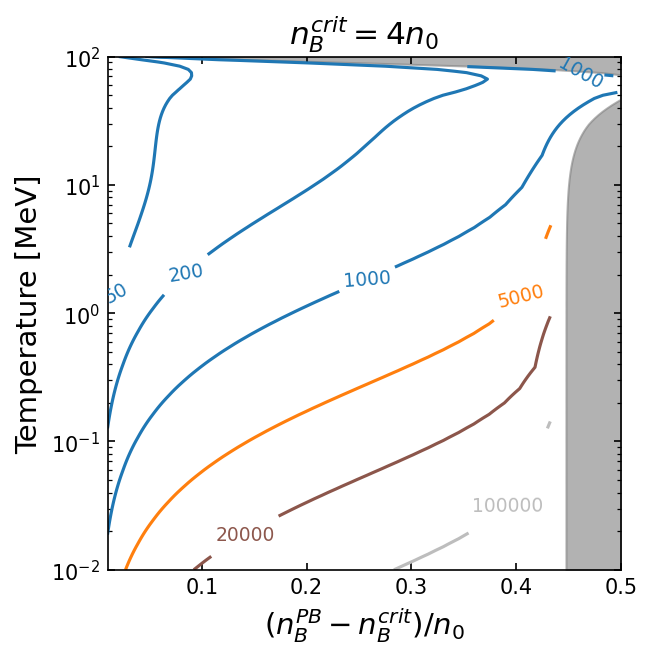

In [110]:
# core3_plot_min.py
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
import RMFsolver.constants as const
from matplotlib.colors import ListedColormap

# ------------------ constants ------------------
n0 = 0.16 * const.MeV_fm**3
nc3 = 3.0 * n0
al = 0.6  # shading alpha

# ------------------ same TT definition as used in solver ------------------
TT = np.logspace(np.log10(0.01), np.log10(100.0), num=160)
NT = TT.size

# Δn grid
N = 30
DD = np.linspace(0.01 * n0, 0.5 * n0, N)

# ------------------ load precomputed data ------------------
V3 = np.load("v_n_crit=4_TTpiece__v6.npy")  # shape (39, 30)
Deln_cut3, T_cut3 = np.load("Shade_n_crit=4_TTpiece__v6.npy", allow_pickle=True)
Cut3 = interp1d(T_cut3, Deln_cut3, kind="linear", fill_value="extrapolate")

# ------------------ build grids ------------------
t = np.linspace(0.0, 1.0, N)
Dlo = 0.01 * n0
Dhi = 0.5 * n0
Dmax = np.minimum(Dhi, Cut3(TT) - 0.015 * n0)
Dmax = np.maximum(Dmax, Dlo)
D_grid = Dlo + (Dmax - Dlo)[:, None] * t[None, :]
T_grid = np.repeat(TT[:, None], N, axis=1)

# ------------------ plot ------------------
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.set_box_aspect(1)

# grey shaded region (unstable)
Dcut = Cut3(TT)
ax.fill_betweenx(TT, Dcut / n0, (0.5 * n0) / n0, color="grey", alpha=al)

# contour plot of velocity
levels = [50, 200, 1000, 5000, 20000, 100000]#np.concatenate([np.arange(40, 640, 80), [2000]])
tab20 = plt.get_cmap("tab20").colors
sat = [tab20[i] for i in [0,2,4,6,8,10,12,14,16,18]]
tab20b = plt.get_cmap("tab20b").colors
tab20c = plt.get_cmap("tab20c").colors
palette = sat + list(tab20b[::2]) + list(tab20c[::2])
cmap = ListedColormap(palette, name="tab20_bright")
def pick(i): return cmap.colors[i % len(cmap.colors)]
LEVEL_COLOR = {lev: pick(k) for k, lev in enumerate(levels)}
for s in (2000, 3000): LEVEL_COLOR[s] = (1,0,0,1)
cs = ax.contour(D_grid / n0, T_grid, V3, levels=levels, cmap = ListedColormap(palette, name="tab20_bright"), linewidths=1.5)
ax.clabel(cs, inline=True, fontsize=9, fmt="%d")

# labels and style
ax.set_xscale("linear")
ax.set_yscale("log")
ax.set_xlim(0.01, 0.5)
ax.set_ylim(0.01, 100)
ax.set_xlabel(r"$(n_B^{PB} - n_B^{crit}) / n_0$", fontsize=14)
ax.set_ylabel("Temperature [MeV]", fontsize=14)
ax.set_title(r"$n_B^{crit} = 4 n_0$", fontsize=15)
ax.tick_params(which="both", direction="in", top=True, right=True)

plt.tight_layout()
#plt.savefig("/Users/janshao/Downloads/v_contour_ncrit3.pdf")
plt.show()

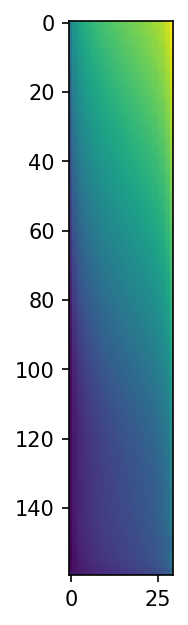

In [111]:
plt.imshow(np.rot90(np.log(V3)[:,:], 0))

In [103]:
from RMFsolver.phase_velocity import vNtoQ_fixB
from tqdm import tqdm

D_test = np.linspace(0.2*n0, 0.25*n0, 10)
vv = []

for Del in tqdm(D_test):

    start = time.time()
    v, _ = vNtoQ_fixB(
        T = TT[49],
        n_crit = 4*n0,
        Deln = Del,
        m_s = 0,
        param = para.paraQMCRMF3,
        NM_type = "PNM",
    )
    end = time.time()
    vv.append(v)
    v=0



00%|█████████████████████████████████████████████████████████████████████████| 10/10 [02:48<00:00, 16.84s/it]

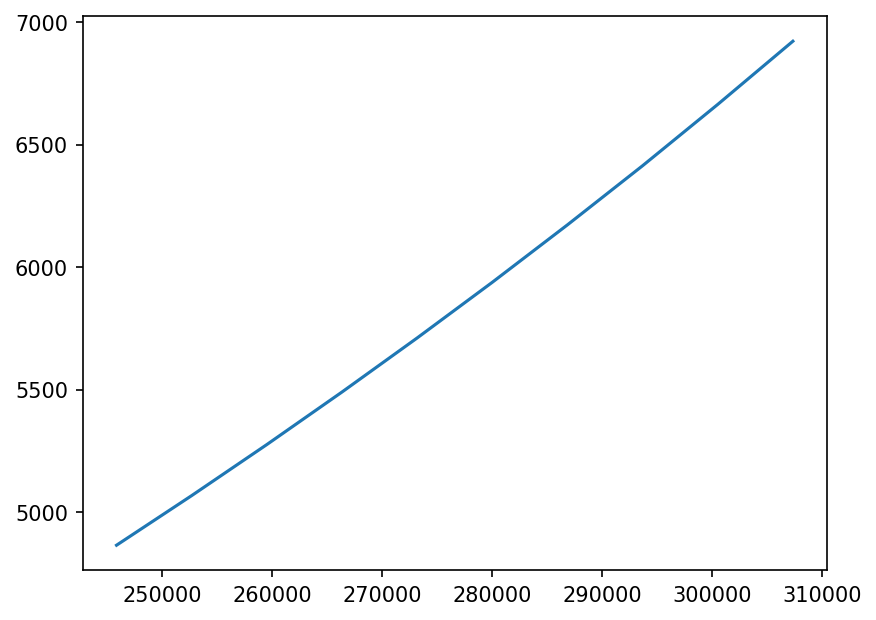

In [104]:
plt.plot(D_test, vv)

In [108]:
import numpy as np

# find index of the zero
i, j = np.argwhere(V3 == 0)[0]

# compute average of 4 adjacent values
V3[i, j] = 0.25 * (
    V3[i-1, j] +
    V3[i+1, j] +
    V3[i, j-1] +
    V3[i, j+1]
)

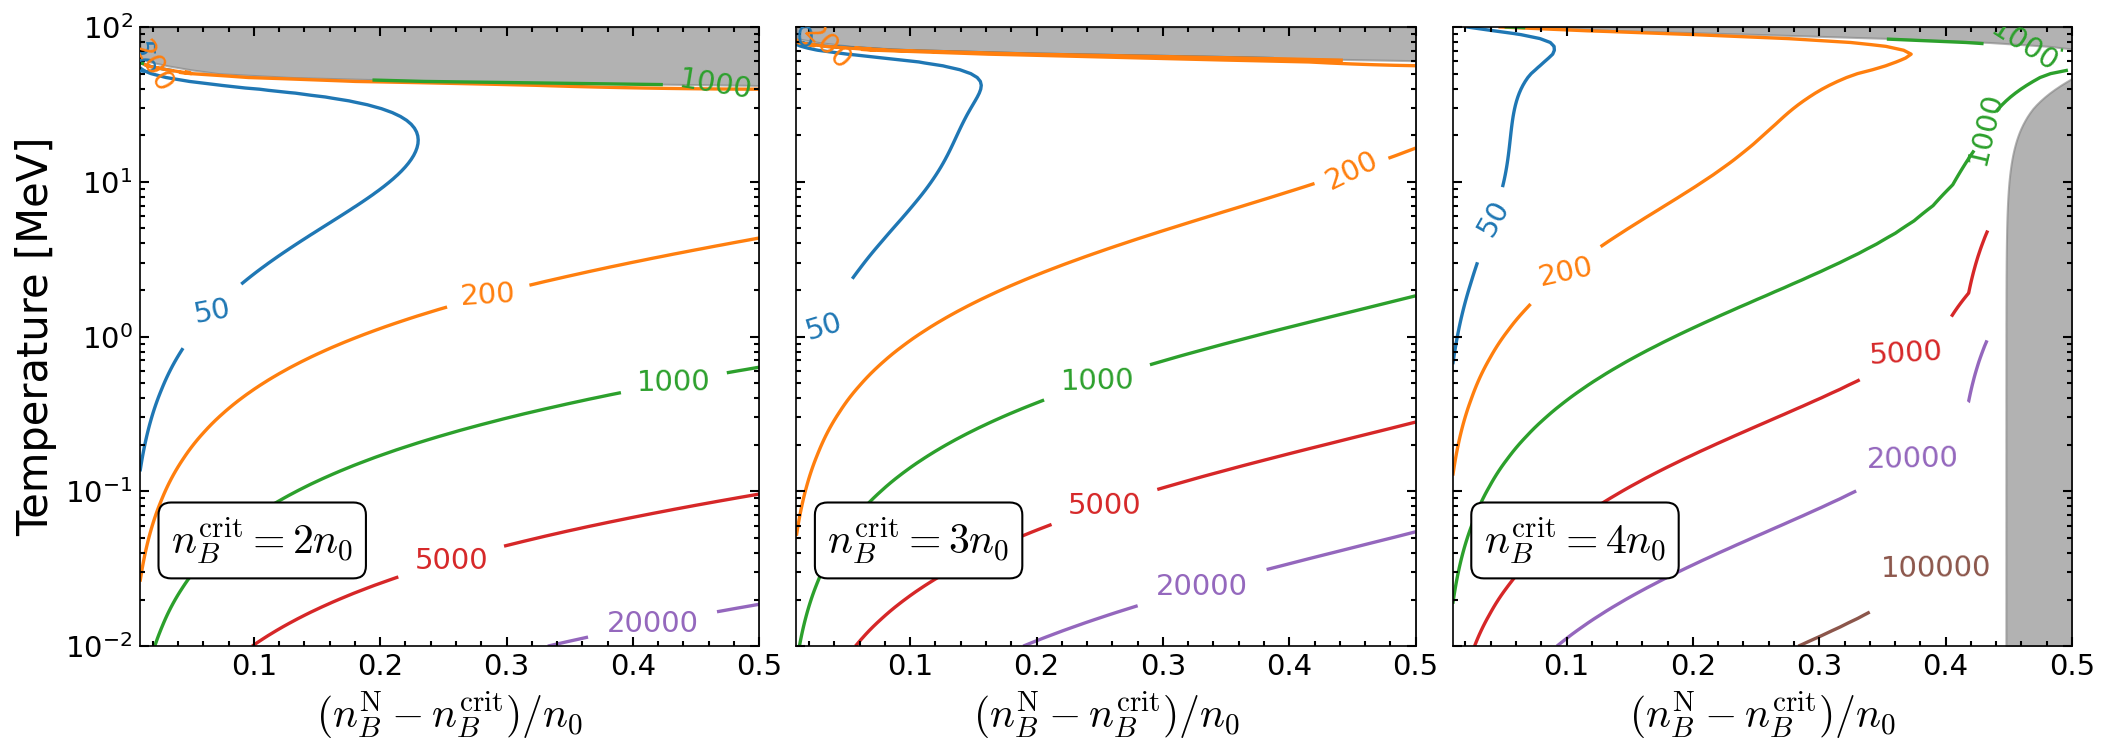

In [123]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFsolve_mu, RMFpressureSYM, RMFpressurePNM, pressure_RMF
from RMFsolver.phase_velocity import P_f, n_B, vNtoQ_nc, vNtoQ_B, PQM
from matplotlib.colors import ListedColormap

plt.rcParams["figure.dpi"] = 150
mpl.rcParams.update({
    "mathtext.fontset": "cm",   # Use Computer Modern for math only
    "mathtext.rm": "serif",
    "mathtext.it": "serif:italic",
    "mathtext.bf": "serif:bold",
})

# ----- physics constants -----
n0 = 0.16 * const.MeV_fm**3
nc2, nc3, nc4 = 2*n0, 3*n0, 4*n0
al = 0.6

# ----- version tag (filenames only) -----
version = "v6"

# ----- fixed temperature axis (for axes only; we do NOT modify V data) -----
TT = np.logspace(np.log10(0.01), np.log10(100.0), num=160)

# ----- shaded region interpolants (uses saved TT from shade files) -----
Deln_cut2, T_cut2 = np.load(f"Shade_n_crit=2_TTpiece__{version}.npy", allow_pickle=True)
Cut2 = interp1d(T_cut2, Deln_cut2, kind="linear", fill_value="extrapolate")

Deln_cut3, T_cut3 = np.load(f"Shade_n_crit=3_TTpiece__{version}.npy", allow_pickle=True)
Cut3 = interp1d(T_cut3, Deln_cut3, kind="linear", fill_value="extrapolate")

Deln_cut4, T_cut4 = np.load(f"Shade_n_crit=4_TTpiece__{version}.npy", allow_pickle=True)
Cut4 = interp1d(T_cut4, Deln_cut4, kind="linear", fill_value="extrapolate")

# ====== log-spaced contour levels (visual only; does not touch data) -----
_levels = [50, 200, 1000, 5000, 20000, 100000] #np.array([50*5**i for i in range(6)]) #np.logspace(np.log10(40), np.log10(40000), 6)
levels_1 = np.unique(np.round(_levels).astype(int))  # for 2 n0
levels_2 = levels_1                                  # for 3 n0
levels_3 = levels_1                                  # for 4 n0
ALL_LEVELS = np.unique(np.concatenate([levels_1, levels_2, levels_3]))

# ----- bright palette (visual only) -----
tab20 = plt.get_cmap("tab20").colors
sat = [tab20[i] for i in [0,2,4,6,8,10,12,14,16,18]]
tab20b = plt.get_cmap("tab20b").colors
tab20c = plt.get_cmap("tab20c").colors
palette = sat + list(tab20b[::2]) + list(tab20c[::2])
cmap = ListedColormap(palette, name="tab20_bright")
def pick(i): return cmap.colors[i % len(cmap.colors)]
LEVEL_COLOR = {lev: pick(k) for k, lev in enumerate(ALL_LEVELS)}
for s in (2000, 3000): LEVEL_COLOR[s] = (1,0,0,1)

def contour_with_fixed_colors(ax, X, Y, Z, levels, **kwargs):
    cols = [LEVEL_COLOR[lev] for lev in levels]
    cs = ax.contour(X, Y, Z, levels=levels, colors=cols, **kwargs)
    ax.clabel(cs, inline=True, fontsize=14, fmt="%d")
    return cs

# 1 x 3 layout 
fig, axs = plt.subplots(1, 3, figsize=(14, 5.2), sharey=True)
plt.subplots_adjust(left=0.06, right=0.98, bottom=0.12, top=0.95, wspace=0.06)
for ax in axs:
    ax.set_box_aspect(1)

ax2, ax3, ax4 = axs  # 2n0, 3n0, 4n0

# ------------------ panel 1: n_crit = 2 n0 ------------------
V2 = np.load(f"v_n_crit=2_TTpiece__{version}.npy", allow_pickle=True)
N2D = V2.shape[1]
t2  = np.linspace(0.0, 1.0, N2D)

Dlo   = 0.01 * n0
Dmax2 = np.minimum(0.5 * n0, Cut2(TT) - 0.015 * n0)   # <- same rule as others
Dmax2 = np.maximum(Dmax2, Dlo)
D_grid2 = Dlo + (Dmax2 - Dlo)[:, None] * t2[None, :]
T_grid2 = np.repeat(TT[:, None], N2D, axis=1)

Dcut2 = Cut2(TT)
ax2.fill_betweenx(TT, Dcut2/n0, (0.5*n0)/n0, color="grey", alpha=al, zorder=0)
contour_with_fixed_colors(ax2, D_grid2/n0, T_grid2, V2, levels_1, linewidths=1.6, zorder=1)
ax2.set_xlim(0.01, 0.5)
ax2.set_ylim(0.01, 100)
ax2.annotate(r"$n_B^{\mathrm{crit}} = 2 n_0$", xy=(0.05, 0.15), xycoords='axes fraction',
             fontsize=20, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black"))

# ------------------ panel 2: n_crit = 3 n0 ------------------
V3 = np.load(f"v_n_crit=3_TTpiece__{version}.npy", allow_pickle=True)
N3D = V3.shape[1]
t3  = np.linspace(0.0, 1.0, N3D)

Dlo   = 0.01 * n0
Dmax3 = np.minimum(0.5 * n0, Cut3(TT) - 0.015 * n0)
Dmax3 = np.maximum(Dmax3, Dlo)
D_grid3 = Dlo + (Dmax3 - Dlo)[:, None] * t3[None, :]
T_grid3 = np.repeat(TT[:, None], N3D, axis=1)

Dcut3 = Cut3(TT)
ax3.fill_betweenx(TT, Dcut3/n0, (0.5*n0)/n0, color="grey", alpha=al, zorder=0)
contour_with_fixed_colors(ax3, D_grid3/n0, T_grid3, V3, levels_2, linewidths=1.6, zorder=1)
ax3.set_xlim(0.01, 0.5)
ax3.set_ylim(0.01, 100)
ax3.annotate(r"$n_B^{\mathrm{crit}} = 3 n_0$", xy=(0.05, 0.15), xycoords='axes fraction',
             fontsize=20, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black"))

# ------------------ panel 3: n_crit = 4 n0 ------------------
V4 = np.load(f"v_n_crit=4_TTpiece__{version}.npy", allow_pickle=True)
N4D = V4.shape[1]
t4  = np.linspace(0.0, 1.0, N4D)

Dmax4 = np.minimum(0.5 * n0, Cut4(TT) - 0.015 * n0)
Dmax4 = np.maximum(Dmax4, Dlo)
D_grid4 = Dlo + (Dmax4 - Dlo)[:, None] * t4[None, :]
T_grid4 = np.repeat(TT[:, None], N4D, axis=1)

Dcut4 = Cut4(TT)
ax4.fill_betweenx(TT, Dcut4/n0, (0.5*n0)/n0, color="grey", alpha=al, zorder=0)
contour_with_fixed_colors(ax4, D_grid4/n0, T_grid4, V4, levels_3, linewidths=1.6, zorder=1)
ax4.set_xlim(0.01, 0.5)
ax4.set_ylim(0.01, 100)
ax4.annotate(r"$n_B^{\mathrm{crit}} = 4 n_0$", xy=(0.05, 0.15), xycoords='axes fraction',
             fontsize=20, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black"))

# ---------- axes labels & ticks ----------
ax2.set_ylabel("Temperature [MeV]", fontsize=20)
for ax in (ax2, ax3, ax4):
    ax.set_xlabel(r"$(n_B^{\mathrm{N}} - n_B^{\mathrm{crit}}) / n_0$", fontsize=20)
    ax.minorticks_on()
    ax.tick_params(which='both', direction='in', top=True, right=True,
                   length=4.5, width=1.0, labelsize=14)
    ax.tick_params(which='minor', length=2.5)
    ax.set_yscale("log")

plt.savefig("1by3_Grid_log_new.pdf")
# plt.show()

# Obtaining values for $dP/dr$

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.interpolate import interp1d
from fractions import Fraction

# Read CSV (skip the header row if it exists)
df1 = pd.read_csv("pressure_of_radius_pMeV4_3n0.csv")
df2 = pd.read_csv("pressure_of_radius_pMeV4_4n0.csv")
df3 = pd.read_csv("pressure_of_radius_pMeV4_4.5n0.csv")

# Convert the first column (fractions as strings) to floats
radius1 = df1.iloc[:, 0].apply(lambda s: eval(str(s)))  # turns "1/100000" into 1/100000.0
pressure1 = df1.iloc[:, 1]

radius2 = df2.iloc[:, 0].apply(lambda s: eval(str(s)))  # turns "1/100000" into 1/100000.0
pressure2 = df2.iloc[:, 1]

radius3 = df3.iloc[:, 0].apply(lambda s: eval(str(s)))  # turns "1/100000" into 1/100000.0
pressure3 = df3.iloc[:, 1]

# Convert to numpy arrays if needed
radius1 = radius1.to_numpy(dtype=float)
radius2 = radius2.to_numpy(dtype=float)
radius3 = radius3.to_numpy(dtype=float)
pressure1 = pressure1.to_numpy(dtype=float)
pressure2 = pressure2.to_numpy(dtype=float)
pressure3 = pressure3.to_numpy(dtype=float)

P_of_r1 = interp1d(radius1, pressure1, kind="linear", fill_value="extrapolate")
P_of_r2 = interp1d(radius2, pressure2, kind="linear", fill_value="extrapolate")
P_of_r3 = interp1d(radius3, pressure3, kind="linear", fill_value="extrapolate")

r_test1 = np.linspace(radius1.min(), radius1.max(), 100)
r_test2 = np.linspace(radius2.min(), radius2.max(), 100)
r_test3 = np.linspace(radius3.min(), radius3.max(), 100)
P_test1 = np.array([P_of_r1(ele) for ele in r_test1])
P_test2 = np.array([P_of_r2(ele) for ele in r_test2])
P_test3 = np.array([P_of_r3(ele) for ele in r_test3])

In [37]:
import numpy as np
import time
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import fsolve, approx_fprime, root_scalar, root, least_squares
from numdifftools import Gradient, Derivative
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFsolve_mu, RMFpressureSYM, RMFpressurePNM, pressure_RMF
from RMFsolver.phase_velocity import P_f, vNtoQ_Pc, vNtoQ_B, vNtoQ_nc, PQM, PQM_em, Get_Delta_n_max, Get_Delta_P_max, _find_muB_muK_star

def PNM(mu_B, Temp, param=para.paraQMCRMF3, ):
    pre = RMFpressurePNM(
        input_num = mu_B,
        input_type = "muB", 
        Trmf = Temp, 
        para = param, 
        sigma_init = 30, 
        w0_init = 20, 
        r03_init = -3, 
        mub_init = 990,
        verb = False
        )
    return float(pre.item())

def PNM_n(nB, Temp):
    pre = RMFpressurePNM(
        input_num = nB,
        input_type = "nB", 
        Trmf = Temp, 
        para = param, 
        sigma_init = 30, 
        w0_init = 20, 
        r03_init = -3, 
        mub_init = 990,
        verb = False
        )
    return float(pre.item())

n0 = 0.16 * const.MeV_fm**3

T = 15
n_kink1 = 3.0 * n0
n_kink2 = 4.0 * n0
n_kink3 = 4.5 * n0
m_s = 0
param = para.paraQMCRMF3
NM_type = "PNM"

# solve for p kink
P_kink1 = PNM_n(n_kink1, T)
P_kink2 = PNM_n(n_kink2, T)
P_kink3 = PNM_n(n_kink3, T)

# solve for r kink
r_kink1 = fsolve(lambda x: P_of_r1(x) - P_kink1, 3)[0]
r_kink2 = fsolve(lambda x: P_of_r2(x) - P_kink2, 3)[0]
r_kink3 = fsolve(lambda x: P_of_r3(x) - P_kink3, 3)[0]

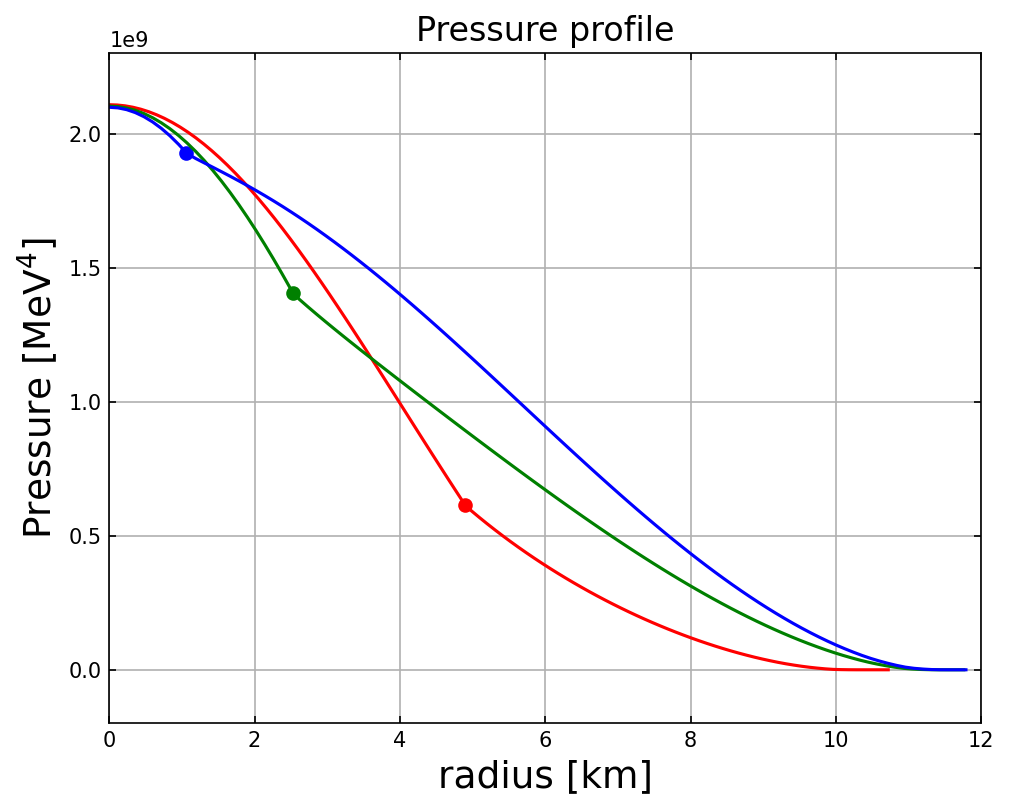

In [38]:
plt.figure(figsize=[7.5, 5.8])
plt.rcParams["figure.dpi"] = 150

plt.plot(r_test1, P_test1, 'r')
plt.plot(r_test2, P_test2, 'g')
plt.plot(r_test3, P_test3, 'b')

plt.scatter(r_kink1, P_kink1, c='r')
plt.scatter(r_kink2, P_kink2, c='g')
plt.scatter(r_kink3, P_kink3, c='b')

#plt.scatter(6.1, P_of_r(6.1), marker="*", c='r', s=100)
#plt.text(6.2, P_of_r(6.1)*1.1, rf"Critical", fontsize=16)
#plt.plot(radius, pressure, 'b')

plt.title("Pressure profile", fontsize = 16)
plt.xlabel(rf"radius [km]", fontsize = 18)
plt.ylabel(rf"Pressure [MeV$^4$]", fontsize = 18)

plt.xlim(0, 12)
plt.ylim(-0.2e+9, 2.3e+9)
plt.tick_params(which='both', direction='in', top=True, right=True)

plt.grid()
plt.show()

In [44]:
epsilon = 0.01 # km
dP_dr1_N = (P_of_r1(r_kink1 + epsilon) - P_of_r1(r_kink1)) / epsilon
dP_dr2_N = (P_of_r2(r_kink2 + epsilon) - P_of_r2(r_kink2)) / epsilon
dP_dr3_N = (P_of_r3(r_kink3 + epsilon) - P_of_r3(r_kink3)) / epsilon

dP_dr1_Q = (P_of_r1(r_kink1) - P_of_r1(r_kink1 - epsilon)) / epsilon
dP_dr2_Q = (P_of_r2(r_kink2) - P_of_r2(r_kink2 - epsilon)) / epsilon
dP_dr3_Q = (P_of_r3(r_kink3) - P_of_r3(r_kink3 - epsilon)) / epsilon

np.mean(np.array([dP_dr1_N, dP_dr2_N, dP_dr3_N]))/1e8

np.float64(-3.556631226884087)

# Sommerfeld

In [56]:
def _kF(mu, m):
    dm = mu*mu - m*m
    return np.sqrt(dm) if dm > 0.0 else 0.0

def _Ek(k, m):
    return np.sqrt(k*k + m*m)

def _log1p_exp_neg(a):
    # stable log(1 + exp(-a))
    if a > 50.0:
        return np.exp(-a)
    if a < -50.0:
        return -a
    return np.log1p(np.exp(-a))

def _smoothstep01(x):
    # C^1 smooth blend on [0,1]
    x = 0.0 if x < 0.0 else (1.0 if x > 1.0 else x)
    return x*x*(3.0 - 2.0*x)

def Tswitch_free_pressure(mu, m, rtol = 1e-6, band = 1.25):
    """
    Return (T_lo, T_hi) to blend T=0 pressure with the finite-T integral.

    Logic:
    - If mu <= m (non-degenerate): use integral only.
    - If mu > m (degenerate): set switch where O(T^2) term changes P by ≲ rtol*P0.
    """
    mu = float(mu); m = float(m)

    if mu <= m:
        return (0.0, 0.0)

    # exact T=0 pressure (degenerate Fermi gas)
    if m == 0.0:
        P0 = mu**4 / (12.0*np.pi**2)
        f  = (mu*mu) / (np.pi**2)
    else:
        kF = _kF(mu, m)
        P0 = ((2.0/3.0 * kF**3 - m*m * kF) * mu
              + m**4 * np.log((kF + mu) / max(m, 1e-300))) / (8.0*np.pi**2)
        f  = (mu * kF) / (np.pi**2)

    if P0 <= 0.0 or f <= 0.0:
        return (0.0, 0.0)

    T_star = np.sqrt((6.0 * rtol * P0) / (np.pi**2 * f))
    return (T_star / band, T_star * band)

# free-fermion pressure
def P_f_test(mu, m, Tem, upB=np.inf, rtol=1e-6, Sommerfeld=True):
    """
    Pressure of a single free fermion (particles + antiparticles).

    - If Sommerfeld=True: use Sommerfeld O(T^2) approximation:
        P(T) = P0(mu,m) + (pi^2/6) T^2 f(mu,m)
      with P0 the exact T=0 pressure and f(mu,m)=mu*kF/pi^2 (massive) or mu^2/pi^2 (massless).

    - If Sommerfeld=False: use the original adaptive T-switch + finite-T integral
      and smoothstep blend (code kept exactly as before).
    """
    mu = float(mu); m = float(m); Tem = float(Tem)

    # ---- Sommerfeld mode (fast) ----
    if Sommerfeld:
        if Tem < 0.0:
            raise RuntimeError("Negative Temperature")

        # P0(mu,m)
        if mu <= m:
            P0 = 0.0
        elif m == 0.0:
            P0 = mu**4 / (12.0 * np.pi**2)
        else:
            kF = np.sqrt(max(mu*mu - m*m, 0.0))
            P0 = ((2.0*kF**3 - 3.0*m*m*kF)*mu
                  + 3.0*m**4*np.log((kF + mu)/max(m, 1e-300))) / (24.0*np.pi**2)

        # fP(mu,m)
        if mu <= m:
            fP = 0.0
        elif m == 0.0:
            fP = (mu*mu) / (np.pi**2)
        else:
            kF = np.sqrt(max(mu*mu - m*m, 0.0))
            fP = (mu * kF) / (np.pi**2)

        return P0 + (np.pi**2 / 6.0) * (Tem*Tem) * fP

    # ======================================================================
    # === Original method (Sommerfeld=False): KEEP EXACTLY AS BEFORE below ===
    # ======================================================================

    # ---- exact T=0 pressure ----
    if Tem < 0:
        raise RuntimeError("Negative Temperature")
    if Tem == 0.0:
        if mu <= m:
            return 0.0
        if m == 0.0:
            return mu**4 / (12.0*np.pi**2)
        kF = _kF(mu, m)
        return ((2.0*kF**3 - 3.0*m*m*kF)*mu + 3.0*m**4*np.log((kF + mu)/max(m, 1e-300))) / (24.0*np.pi**2)

    # ---- adaptive switch band ----
    T_lo, T_hi = Tswitch_free_pressure(mu, m, rtol=rtol, band=1.25)

    # ---- check regime ----
    if T_hi == 0.0:
        use_blend = False
    else:
        use_blend = (T_lo < Tem < T_hi)

    if not use_blend and Tem <= T_lo:
        if mu <= m:
            return 0.0
        if m == 0.0:
            return mu**4 / (12.0*np.pi**2)
        kF = _kF(mu, m)
        return ((2.0*kF**3 - 3.0*m*m*kF)*mu + 3.0*m**4*np.log((kF + mu)/max(m, 1e-300))) / (24.0*np.pi**2)

    # ---- finite-T integral ----
    def _P_int(Tloc):
        def integrand(k):
            Ek = _Ek(k, m)
            a  = (Ek - mu)/Tloc
            b  = (Ek + mu)/Tloc
            return Tloc * (_log1p_exp_neg(a) + _log1p_exp_neg(b)) * (k*k)
        ub = np.inf if (upB is None or not np.isfinite(float(upB))) else float(upB)
        Pint, _ = quad(integrand, 0.0, ub, epsabs=1e-10, epsrel=1e-8, limit=200)
        return Pint / (np.pi**2)

    if not use_blend and Tem >= T_hi:
        return _P_int(Tem)

    # ---- blend inside the band on log(Tem) ----
    if mu <= m:
        P0 = 0.0
    elif m == 0.0:
        P0 = mu**4 / (12.0*np.pi**2)
    else:
        kF = _kF(mu, m)
        P0 = ((2.0*kF**3 - 3.0*m*m*kF)*mu + 3.0*m**4*np.log((kF + mu)/max(m,1e-300))) / (24.0*np.pi**2)

    P_int = _P_int(Tem)
    x = (np.log(Tem) - np.log(T_lo)) / (np.log(T_hi) - np.log(T_lo))
    w = _smoothstep01(x)
    return (1.0 - w)*P0 + w*P_int

In [75]:
from RMFsolver.phase_velocity import P_f

T_list = np.logspace(-3,2,100)
m = 939.0
mu = 1100.0

P_adaptive = [P_f_test(mu, m, TT, Sommerfeld = False) for TT in T_list]
P_Sommerfeld = [P_f_test(mu, m, TT,) for TT in T_list]
P_comp = [P_f(mu, m, TT) for TT in T_list]

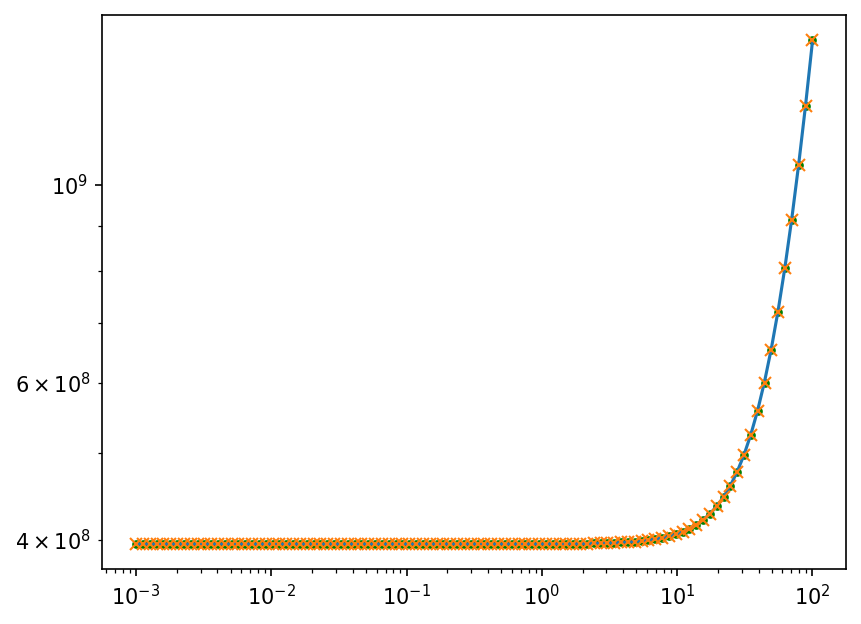

In [80]:
plt.scatter(T_list, P_adaptive, c='g', s=10)
plt.plot(T_list, P_Sommerfeld, '-')
plt.plot(T_list, P_comp, 'x')
plt.xscale('log')
plt.yscale('log')

* see how gray region appear under new method of fixing $U_{\rm bag}$, and why it takes that shape
* do $z(t)$ plots for $z_0 = 1$ km, $|dP/dr| = 2\times 10^8\,\rm{MeV}^4\cdot \rm{km}^{-1}$ $\boxed{\checkmark}$
* write some text for $z(t)$ stuff $\boxed{\checkmark}$
* do contour plot for $3n_0$ but with larger x axis window $\boxed{\checkmark}$

In [3]:
import numpy as np
import time
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import fsolve, approx_fprime, root_scalar, root, least_squares
from numdifftools import Gradient, Derivative
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFsolve_mu, RMFpressureSYM, RMFpressurePNM, pressure_RMF
from RMFsolver.phase_velocity import P_f, vNtoQ_Pc, vNtoQ_B, vNtoQ_nc, PQM, PQM_em, Get_Delta_n_max, Get_Delta_P_max, _find_muB_muK_star, z_time_evolution2

n0 = 0.16 * const.MeV_fm**3

In [ ]:

def PNM(mu_B, Temp, param=para.paraQMCRMF3, ):
    pre = RMFpressurePNM(
        input_num = mu_B,
        input_type = "muB", 
        Trmf = Temp, 
        para = param, 
        sigma_init = 30, 
        w0_init = 20, 
        r03_init = -3, 
        mub_init = 990,
        verb = False
        )
    return float(pre.item())

def PNM_n(nB, Temp, param = para.paraQMCRMF3):
    pre = RMFpressurePNM(
        input_num = nB,
        input_type = "nB", 
        Trmf = Temp, 
        para = param, 
        sigma_init = 30, 
        w0_init = 20, 
        r03_init = -3, 
        mub_init = 990,
        verb = False
        )
    return float(pre.item())

n0 = 0.16 * const.MeV_fm**3
dP_over_dr = 2e8 # MeV^4/km
n_crit = 3*n0 
T = 10 # MeV
z0 = 1 #km
t_up = 40 # s
Interp1d_Num = 10
m_s = 0
param = para.paraQMCRMF3
NM_ty = "PNM"
aQmax = True

In [2]:
# 1) calculate P_critical. We define it to be whatever pressure 1km away from the kink
P_crit0 = PNM_n(n_crit, Temp=0)
muB_crit0 = fsolve(lambda x: PNM(x, Temp=0) - P_crit0, 1050)[0]
PQM_solve_for_B = lambda x: PQM(muB_crit0, muK=0, B_one_forth=x, T=0, ms=m_s) - P_crit0
B_SQM = fsolve(PQM_solve_for_B, 180)[0]
muB_crit = fsolve(lambda x: PQM(x, 0, B_SQM, T, m_s) - PNM(x, T), 1050)[0]
P_c = PQM(muB_crit, 0, B_SQM, T, m_s)

In [3]:
# 2) P(r) and locate r_crit from P(r)=P_c
P_of_r = lambda r: P_c + dP_over_dr * (z0 - r)
DelP_max = P_of_r(0)

1.3408765771960325

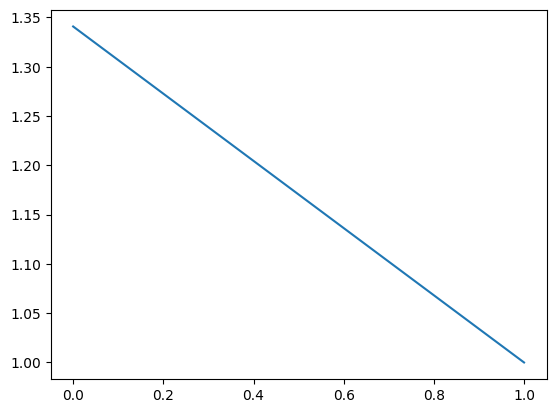

In [4]:
rr = np.linspace(0,1,10)
plt.plot(rr, P_of_r(rr)/P_c)
DelP_max/P_c

In [5]:
# 3) Pre-tabulate v(z) on [0, z0] and build cheap interpolant
Interp1d_Num = max(int(Interp1d_Num), 2)  # need at least 2 points
z_list = np.logspace(-8, 0, Interp1d_Num)

In [11]:
from tqdm import tqdm

def vz_accurate(z):
    # z can be scalar or array; ensure scalar use here
    z = float(np.asarray(z).reshape(()))
    DelP_P_c = P_of_r(z0 - z)
    vel, _ = vNtoQ_Pc(T=T, P_crit=P_c, DelP=float(DelP_P_c) - P_c,
                      m_s=m_s, param=param, NM_type=NM_ty, aQmax=aQmax)
    return float(vel) / 1e3  # km/s

v_list = []
for z in tqdm(z_list):
    v_list.append(vz_accurate(z)) # for z in z_list], dtype=float)



00%|█████████████████████████████████████████████████████████████████████████| 10/10 [01:04<00:00,  6.46s/it]

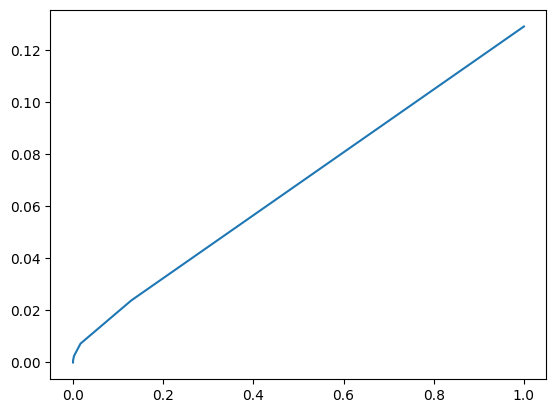

In [12]:
plt.plot(z_list, v_list)

In [15]:
from scipy.interpolate import interp1d
from scipy.integrate import quad, solve_bvp, solve_ivp
from scipy.optimize import fsolve, approx_fprime, root_scalar, root, least_squares, minimize_scalar

# Use linear (more stable with few points). Keep cubic only if you have enough points & smoothness
vz_interp1d = interp1d(z_list, v_list, kind="linear", fill_value="extrapolate")

# 4) ODE: dz/dt = -v(z). Must accept y as 1-D array and return 1-D array
def dzdt(t, y):
    z = float(y[0])
    v = float(vz_interp1d(z))
    return np.array([-v], dtype=float)

# Stop when z hits 0
def hit_z_target(t, y, z_target=0.0):
    return y[0] - z_target

hit_z_target.terminal = True
hit_z_target.direction = 0

t0, t1 = 0.0, float(t_up)
t_eval = np.linspace(t0, t1, 500)

# y0 must be 1-D:
y0 = np.array([z0], dtype=float)

try:
    sol = solve_ivp(
        dzdt, (t0, t1), y0,
        method="RK45",
        t_eval=t_eval,
        events=lambda t, y: hit_z_target(t, y, z_target=0.0),
        rtol=1e-7, atol=1e-9
    )
except Exception as e:
    raise RuntimeError(f"solve_ivp failed with error: {e}") from e

if not sol.success:
    raise RuntimeError(f"Integration failed: {sol.message}")

In [16]:
t = np.array(sol.t, dtype=float)                   # shape (M,)
z = np.array(sol.y[0], dtype=float)

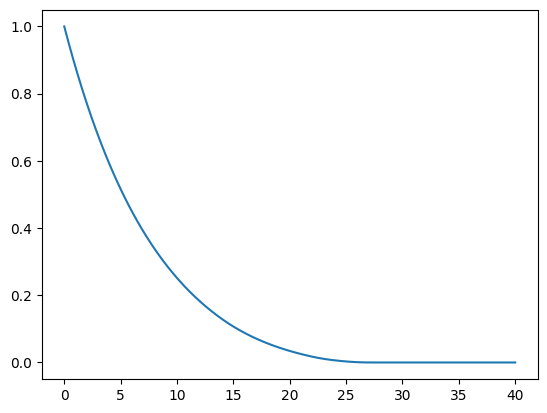

In [17]:
plt.plot(t, z)

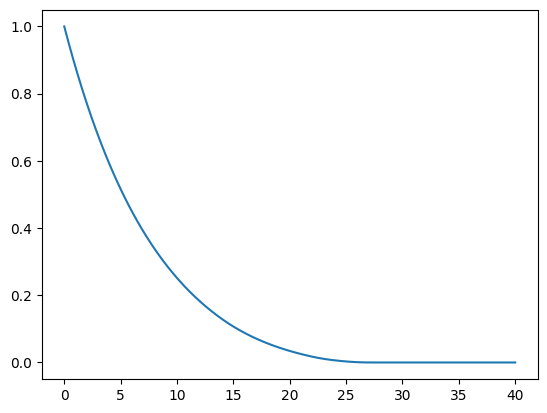

In [4]:
tt, zz = z_time_evolution2(
    dP_over_dr = 2e8, # MeV^4/km
    n_crit = 3*n0, 
    T = 10,  # MeV
    z0 = 1,  #km
    t_up = 40, # s
    Interp1d_Num = 10,
    m_s = 0,
    param = para.paraQMCRMF3,
    NM_type = "PNM",
    aQmax = True,
)
plt.plot(tt, zz)

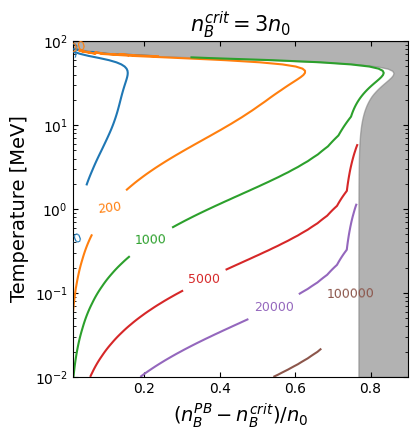

In [25]:
# core3_plot_min.py
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
import RMFsolver.constants as const
from matplotlib.colors import ListedColormap

# ------------------ constants ------------------
n0 = 0.16 * const.MeV_fm**3
nc3 = 3.0 * n0
al = 0.6  # shading alpha

# ------------------ same TT definition as used in solver ------------------
TT = np.logspace(np.log10(0.01), np.log10(100.0), num=160)
NT = TT.size

# Δn grid
N = 30
DD = np.linspace(0.01 * n0, 1.0 * n0, N)

# ------------------ load precomputed data ------------------
V3 = np.load("v_n_crit=3_TTpiece__v8.npy")  # shape (NT', N)
Deln_cut3, T_cut3 = np.load("Shade_n_crit=3_TTpiece__v8.npy", allow_pickle=True)
Cut3 = interp1d(T_cut3, Deln_cut3, kind="linear", fill_value="extrapolate")

# ------------------ build grids ------------------
t = np.linspace(0.0, 1.0, N)
Dlo = 0.01 * n0
Dhi = 1.0 * n0
Dmax = np.minimum(Dhi, Cut3(TT) - 0.005 * n0)
Dmax = np.maximum(Dmax, Dlo)
D_grid = Dlo + (Dmax - Dlo)[:, None] * t[None, :]
T_grid = np.repeat(TT[:, None], N, axis=1)

# ------------------ contour levels ------------------
levels = [50, 200, 1000, 5000, 20000, 100000]

# ------------------ bright palette + fixed level colors ------------------
tab20 = plt.get_cmap("tab20").colors
sat = [tab20[i] for i in [0, 2, 4, 6, 8, 10, 12, 14, 16, 18]]
tab20b = plt.get_cmap("tab20b").colors
tab20c = plt.get_cmap("tab20c").colors
palette = sat + list(tab20b[::2]) + list(tab20c[::2])
cmap = ListedColormap(palette, name="tab20_bright")

def pick(i):
    return cmap.colors[i % len(cmap.colors)]

LEVEL_COLOR = {lev: pick(k) for k, lev in enumerate(levels)}
for s in (2000, 3000):
    LEVEL_COLOR[s] = (1, 0, 0, 1)

def contour_with_fixed_colors(ax, X, Y, Z, levels, **kwargs):
    cols = [LEVEL_COLOR[lev] for lev in levels]
    cs = ax.contour(X, Y, Z, levels=levels, colors=cols, **kwargs)
    ax.clabel(cs, inline=True, fontsize=9, fmt="%d")
    return cs

# ------------------ plot ------------------
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.set_box_aspect(1)

# grey shaded region (unstable)
Dcut = Cut3(TT)
ax.fill_betweenx(TT, Dcut / n0, (1.0 * n0) / n0, color="grey", alpha=al)

# contour plot of velocity (fixed colors per level)
contour_with_fixed_colors(ax, D_grid / n0, T_grid, V3, levels, linewidths=1.5)

# labels and style
ax.set_xscale("linear")
ax.set_yscale("log")
ax.set_xlim(0.01, 0.9)
ax.set_ylim(0.01, 100)
ax.set_xlabel(r"$(n_B^{PB} - n_B^{crit}) / n_0$", fontsize=14)
ax.set_ylabel("Temperature [MeV]", fontsize=14)
ax.set_title(r"$n_B^{crit} = 3 n_0$", fontsize=15)
ax.tick_params(which="both", direction="in", top=True, right=True)

plt.tight_layout()
# plt.savefig("/Users/janshao/Downloads/v_contour_ncrit3.pdf")
plt.show()

In [2]:
from tqdm import tqdm
import numpy as np
import time
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import fsolve, approx_fprime, root_scalar, root, least_squares
from numdifftools import Gradient, Derivative
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFsolve_mu, RMFpressureSYM, RMFpressurePNM, pressure_RMF
from RMFsolver.phase_velocity import P_f, vNtoQ_Pc, vNtoQ_B, vNtoQ_nc, PQM, PQM_em, Get_Delta_n_max, Get_Delta_P_max, _find_muB_muK_star, z_time_evolution2

n0 = 0.16 * const.MeV_fm**3

def PNM(mu_B, Temp):
    if NM_type == "Beta_eq":
        rmf_sol = RMFsolve_mu(mub = mu_B, Trmf = Temp, para = param, 
            sigma_init = 30, w0_init = 20, r03_init = -3, mu_e_init = 50, verb = False
            )
        return (pressure_RMF(rmf_sol)).item()

    elif NM_type == "PNM":
        pre = RMFpressurePNM(input_num = mu_B, input_type = "muB", Trmf = Temp, para = param, 
            sigma_init = 30, w0_init = 20, r03_init = -3, mub_init = 990, verb = False
            )
        return float(pre.item())

    elif NM_type == "SYM":
        pre = RMFpressureSYM(input_num = mu_B, input_type = "muB", Trmf = Temp, para = param, 
            sigma_init = 30, w0_init = 20, mub_init = 990, verb = False
            )
        return float(pre.item())

    else:
        return ValueError("Nuclear matter type not defined.")


def PNM_n(nB, Temp):
    if NM_type == "Beta_eq":
        rmf_sol = RMFsolve(nbext = nB, Trmf = Temp, para = param, 
            sigma_init = 30, w0_init = 20, r03_init = -3, mu_e_init = 50, verb = False
            )
        return (pressure_RMF(rmf_sol)).item()

    elif NM_type == "PNM":
        pre = RMFpressurePNM(input_num = nB, input_type = "nB", Trmf = Temp, para = param, 
            sigma_init = 30, w0_init = 20, r03_init = -3, mub_init = 990, verb = False
            )
        return float(pre.item())

    elif NM_type == "SYM":
        pre = RMFpressureSYM(input_num = nB, input_type = "nB", Trmf = Temp, para = param, 
            sigma_init = 30, w0_init = 20, mub_init = 990, verb = False
            )
        return float(pre.item())

    else:
        return ValueError("Nuclear matter type not defined.")

In [3]:
Deln = 0.4*n0
n_crit = 3*n0
T_list = np.logspace(-2,2,200)
NM_type = "PNM"
param = para.paraQMCRMF3
m_s = 0

muB_N_list = []
muB_Q_list = []
chiK_Q_list = []
nB_N_list = []
nB_Q_list = []

for T in tqdm(T_list):
    # solve for bag constant
    P_crit0 = PNM_n(n_crit, Temp=0)
    muB_crit0 = fsolve(lambda x: PNM(x, Temp=0) - P_crit0, 1050)[0]
    PQM_solve_for_B = lambda x: PQM(muB_crit0, muK=0, B_one_forth=x, T=0, ms=m_s) - P_crit0
    B_SQM = fsolve(PQM_solve_for_B, 180)[0]

    # solve for critical point
    muB_crit = fsolve(lambda x: PQM(x, 0, B_SQM, T, m_s) - PNM(x, T), 1050)[0]
    P_crit = PQM(muB_crit, 0, B_SQM, T, m_s)
    n_crit_T = fsolve(lambda x: PNM_n(x, T) - P_crit, 2*n0)[0]
    DelP = PNM_n(n_crit_T + Deln, T) - P_crit

    # solve for points Q and N at beta eq.
    PNM_minus_PShift = lambda x: PNM(x,T) - P_crit - DelP
    muB_N = fsolve(PNM_minus_PShift, 1050)[0]

    PQM_minus_Pshift = lambda x: PQM(x, 0, B_SQM, T, m_s) - P_crit - DelP
    muB_Q = fsolve(PQM_minus_Pshift, 1050)[0]
    
    # calculating aQstar
    if False:
        epsilon = np.sqrt(np.finfo(float).eps)
        muB_star, muK_star = _find_muB_muK_star(PQM, P_crit + DelP, muB_N, B_SQM, T, m_s)
        PQM_wrap = lambda Mu: PQM(Mu[0], Mu[1], B_SQM, T, m_s)
        grad_Qstar = approx_fprime(np.array([muB_star, muK_star]), PQM_wrap, epsilon)
        nB_Qstar = grad_Qstar[0]
        nK_Qstar = grad_Qstar[1]
        grad_Q = approx_fprime(np.array([muB_Q, 0]), PQM_wrap, epsilon)
        nB_Q = grad_Q[0]
        nK_Q = grad_Q[1]
        aQstar = (nK_Qstar - nK_Q)/nB_Q  
    
    else:
        PQM_muB = lambda Mu: PQM(Mu, 0, B_SQM, T, m_s)
        PQM_muK = lambda Mu: PQM(muB_Q, Mu, B_SQM, T, m_s)
        ddPQM_ddmuK = Derivative(PQM_muK, n=2)
        dPQM_dmuK = Derivative(PQM_muK, n=1)
        dPQM_dmuB = Derivative(PQM_muB, n=1)
        chiK_Q = ddPQM_ddmuK(0)
        nB_Q = dPQM_dmuB(muB_Q)
        nK_Q = dPQM_dmuK(0)
        aQstar = np.sqrt(2*(muB_N - muB_Q)*chiK_Q / nB_Q)
        muK_star = np.sqrt(2 * nB_Q * (muB_N - muB_Q) / chiK_Q)
        PQM_solve_for_muBstar = lambda x: PQM(x, muK_star, B_SQM, T, m_s) - P_crit - DelP
        muB_star = fsolve(PQM_solve_for_muBstar, muB_Q)[0]
    
    
    # calculating aN
    PNM_wrap = lambda x: PNM(x, T)
    dPNM_dmuB = Derivative(PNM_wrap, n=1)
    nB_N = dPNM_dmuB(muB_N)
    aN = (nB_N - nK_Q) / nB_Q 

    muB_N_list.append(muB_N)
    muB_Q_list.append(muB_Q)
    chiK_Q_list.append(chiK_Q)
    nB_N_list.append(nB_N)
    nB_Q_list.append(nB_Q)



00%|███████████████████████████████████████████████████████████████████████| 200/200 [38:34<00:00, 11.57s/it]

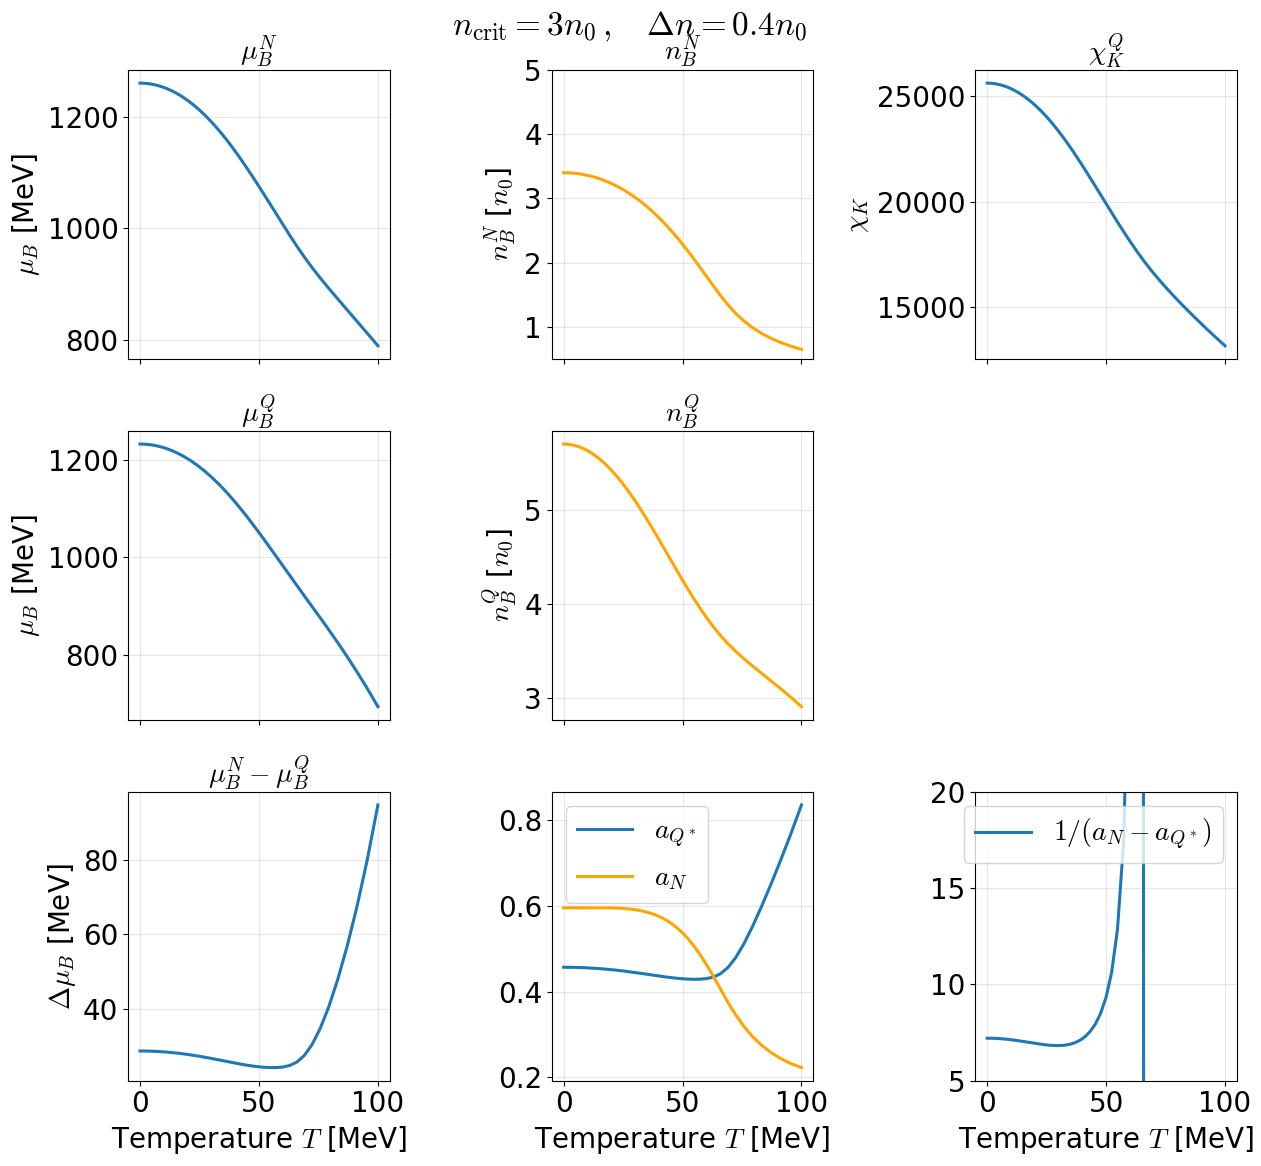

In [14]:
muB_N_list = np.array(muB_N_list)
muB_Q_list = np.array(muB_Q_list)
chiK_Q_list = np.array(chiK_Q_list)
nB_N_list   = np.array(nB_N_list)
nB_Q_list   = np.array(nB_Q_list)

# ---- Normalize number densities by saturation density n0 ----
nB_N_list_n0 = nB_N_list / n0
nB_Q_list_n0 = nB_Q_list / n0

plt.rcParams.update({
    "font.size": 20,
    "axes.labelsize": 20,
    "axes.titlesize": 20,
    "legend.fontsize": 20,
    "lines.linewidth": 2.2,
    "mathtext.fontset": "cm"
})

fig, ax = plt.subplots(3, 3, figsize=(13, 12), sharex=True)

# ---- Row 1 ----
ax[0,0].plot(T_list, muB_N_list)
ax[0,0].set_title(r"$\mu_B^N$")
ax[0,0].set_ylabel(r"$\mu_B$ [MeV]")
ax[0,0].grid(True, alpha=0.3)

ax[0,1].plot(T_list, nB_N_list_n0, 'orange')
ax[0,1].set_ylim(0.5, 5)
ax[0,1].set_title(r"$n_B^N$")
ax[0,1].set_ylabel(r"$n_B^N$ [$n_0$]")
ax[0,1].grid(True, alpha=0.3)

ax[0,2].plot(T_list, chiK_Q_list)
ax[0,2].set_title(r"$\chi_K^Q$")
ax[0,2].set_ylabel(r"$\chi_K$")
ax[0,2].grid(True, alpha=0.3)

# ---- Row 2 ----
ax[1,0].plot(T_list, muB_Q_list)
ax[1,0].set_title(r"$\mu_B^Q$")
ax[1,0].set_ylabel(r"$\mu_B$ [MeV]")
ax[1,0].grid(True, alpha=0.3)

ax[1,1].plot(T_list, nB_Q_list_n0, 'orange')
ax[1,1].set_title(r"$n_B^Q$")
ax[1,1].set_ylabel(r"$n_B^Q$ [$n_0$]")
ax[1,1].grid(True, alpha=0.3)

ax[1,2].axis("off")

# ---- Row 3 ----
ax[2,0].plot(T_list, muB_N_list - muB_Q_list)
ax[2,0].set_title(r"$\mu_B^N - \mu_B^Q$")
ax[2,0].set_ylabel(r"$\Delta \mu_B$ [MeV]")
ax[2,0].set_xlabel(r"$T$ [MeV]")
ax[2,0].grid(True, alpha=0.3)

#ax[2,1].plot(T_list, nB_N_list/nB_Q_list, 'orange')
#ax[2,1].set_title(r"$a_N$")
#ax[2,1].set_ylabel(r"$\Delta \mu_B$ [MeV]")
#ax[2,1].set_xlabel(r"$T$ [MeV]")
#ax[2,1].grid(True, alpha=0.3)

ax[2,1].plot(T_list, np.sqrt(2*(muB_N_list - muB_Q_list)*chiK_Q_list/nB_Q_list), label = r"$a_{Q^*}$")
ax[2,1].plot(T_list, nB_N_list/nB_Q_list, 'orange', label = r"$a_N$")
#ax[2,1].set_title(r"$a_{Q^*}$")
#ax[2,1].set_ylabel(r"$\Delta \mu_B$ [MeV]")
ax[2,1].set_xlabel(r"$T$ [MeV]")
ax[2,1].grid(True, alpha=0.3)
ax[2,1].legend()

ax[2,2].plot(T_list, 1/(nB_N_list/nB_Q_list - np.sqrt(2*(muB_N_list - muB_Q_list)*chiK_Q_list/nB_Q_list)), label = r"$1/(a_N - a_{Q^*})$")
#ax[2,2].plot(T_list, nB_N_list/nB_Q_list, 'orange', label = r"$a_N$")
#ax[2,2].set_title(r"$a_{Q^*}$")
#ax[2,2].set_ylabel(r"$\Delta \mu_B$ [MeV]")
ax[2,2].set_xlabel(r"$T$ [MeV]")
ax[2,2].set_ylim(5, 20)
ax[2,2].grid(True, alpha=0.3)
ax[2,2].legend()

#ax[2,1].axis("off")
#ax[2,2].axis("off")

# ---- Shared X label ----
for j in range(3):
    ax[2,j].set_xlabel(r"Temperature $T$ [MeV]")

plt.tight_layout()
plt.subplots_adjust(top=0.93)
fig.suptitle(r"$n_{\rm crit} = 3n_0\,,\quad \Delta n = 0.4n_0$", fontsize=24)
plt.show()

* pull out RMF VEVs, effective mass and so on while increasing temperature, see if interesting things happen starting at $T\simeq 60$ MeV
* upload the velocity formula with parameter $\lambda$ or $\xi$, and add its derivation in the sup material, try make it streamlined; also include derivation of $a'(0+)$
* 

In [28]:
from tqdm import tqdm
import numpy as np
import time
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import fsolve, approx_fprime, root_scalar, root, least_squares
from numdifftools import Gradient, Derivative
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFpressurePNM, _set_couplings, RMFsolvePNM, RMFsolvePNM_mu
from RMFsolver.phase_velocity import P_f, vNtoQ_nc, PQM, _find_muB_muK_star

n0 = 0.16 * const.MeV_fm**3

def PNM(mu_B, Temp):
    if NM_type == "Beta_eq":
        rmf_sol = RMFsolve_mu(mub = mu_B, Trmf = Temp, para = param, 
            sigma_init = 30, w0_init = 20, r03_init = -3, mu_e_init = 50, verb = False
            )
        return (pressure_RMF(rmf_sol)).item()

    elif NM_type == "PNM":
        pre = RMFpressurePNM(input_num = mu_B, input_type = "muB", Trmf = Temp, para = param, 
            sigma_init = 30, w0_init = 20, r03_init = -3, mub_init = 990, verb = False
            )
        return float(pre.item())

    elif NM_type == "SYM":
        pre = RMFpressureSYM(input_num = mu_B, input_type = "muB", Trmf = Temp, para = param, 
            sigma_init = 30, w0_init = 20, mub_init = 990, verb = False
            )
        return float(pre.item())

    else:
        return ValueError("Nuclear matter type not defined.")


def PNM_n(nB, Temp):
    if NM_type == "Beta_eq":
        rmf_sol = RMFsolve(nbext = nB, Trmf = Temp, para = param, 
            sigma_init = 30, w0_init = 20, r03_init = -3, mu_e_init = 50, verb = False
            )
        return (pressure_RMF(rmf_sol)).item()

    elif NM_type == "PNM":
        pre = RMFpressurePNM(input_num = nB, input_type = "nB", Trmf = Temp, para = param, 
            sigma_init = 30, w0_init = 20, r03_init = -3, mub_init = 990, verb = False
            )
        return float(pre.item())

    elif NM_type == "SYM":
        pre = RMFpressureSYM(input_num = nB, input_type = "nB", Trmf = Temp, para = param, 
            sigma_init = 30, w0_init = 20, mub_init = 990, verb = False
            )
        return float(pre.item())

    else:
        return ValueError("Nuclear matter type not defined.")

In [70]:
Deln = 0.4*n0
n_crit0 = 3*n0
T_list = np.logspace(-2,2,200)
NM_type = "PNM"
param = para.paraQMCRMF3
m_s = 0

sigma_list = []
w0_list = []
r03_list = []
mub_list = []
sol_table_list = []

global ms, mw, mr, b, c, Mn, mB
global gsn, gs, gw, gr, I3
global zet, xi, bar
global b1, b2, b3, a1, a2, a3, a4, a5, a6
global me, upB, P_offset

# Assignments
ms = param[1][0]
mw = param[1][1]
mr = param[1][2]

b = param[6][0]
c = param[6][1]
Mn = param[6][2]

mB = param[0]
gsn = param[3][0]
gs = param[3]
gw = param[4]
gr = param[5]
I3 = param[2]

zet = param[7][0]
xi = param[8][0]
bar = -1

b1, b2, b3, a1, a2, a3, a4, a5, a6 = param[9]

me = 0.511  # Electron mass in MeV
upB = 5000  # Upper integration bound

In [84]:
muB_N_list = []
muB_Q_list = []
muB_crit_list = []
P_crit_list = []
DelP_list = []
n_crit_T_list = []

P_crit0 = PNM_n(n_crit0, Temp=0)
muB_crit0 = fsolve(lambda x: PNM(x, Temp=0) - P_crit0, 1050)[0]
PQM_solve_for_B = lambda x: PQM(muB_crit0, muK=0, B_one_forth=x, T=0, ms=m_s) - P_crit0
B_SQM = fsolve(PQM_solve_for_B, 180)[0]

for TT in tqdm(T_list):
    # solve for critical point
    muB_crit = fsolve(lambda x: PQM(x, 0, B_SQM, TT, m_s) - PNM(x, TT), 1050)[0]
    muB_crit_list.append(muB_crit)
    P_crit = PQM(muB_crit, 0, B_SQM, TT, m_s)
    P_crit_list.append(P_crit)
    n_crit_T = fsolve(lambda x: PNM_n(x, TT) - P_crit, 2*n0)[0]
    n_crit_T_list.append(n_crit_T)
    DelP = PNM_n(n_crit_T + Deln, TT) - P_crit
    DelP_list.append(DelP)

    # solve for points Q and N at beta eq.
    PNM_minus_PShift = lambda x: PNM(x,TT) - P_crit - DelP
    muB_N = fsolve(PNM_minus_PShift, 1050)[0]
    muB_N_list.append(muB_N)
    PQM_minus_Pshift = lambda x: PQM(x, 0, B_SQM, TT, m_s) - P_crit - DelP
    muB_Q = fsolve(PQM_minus_Pshift, 1050)[0]
    muB_Q_list.append(muB_Q)
    
    sol_table_tmp = RMFsolvePNM(
        nbext = n_crit_T + Deln,
        Trmf = TT,
        para = param,
    )
    sol_table_list.append(sol_table_tmp)


00%|███████████████████████████████████████████████████████████████████████| 200/200 [24:57<00:00,  7.49s/it]

In [86]:
sigma_list = []
w0_list = []
r03_list = []
mub_list = []

for vevs in sol_table_list:
    sigma_list.append(vevs[0][0])
    w0_list.append(vevs[0][1])
    r03_list.append(vevs[0][2])
    mub_list.append(vevs[0][3])

sigma_list = np.array(sigma_list)
w0_list = np.array(w0_list)
r03_list = np.array(r03_list)
mub_list = np.array(mub_list)
muB_N_list = np.array(muB_N_list)
muB_Q_list = np.array(muB_Q_list)
muB_crit_list = np.array(muB_crit_list)
P_crit_list = np.array(P_crit_list)
DelP_list = np.array(DelP_list)
n_crit_T_list = np.array(n_crit_T_list)

BI = 0 # neutrons

m_eff_list = np.array([mB[BI] - gs[BI]*sigma_list[i] for i in range(len(T_list))])
mub_eff_list = np.array([mub_list[i] - gw[BI]*w0_list[i] - I3[BI]*gr[BI]*r03_list[i] for i in range(len(T_list))])
muB_N_eff_list = np.array([muB_N_list[i] - gw[BI]*w0_list[i] - I3[BI]*gr[BI]*r03_list[i] for i in range(len(T_list))])

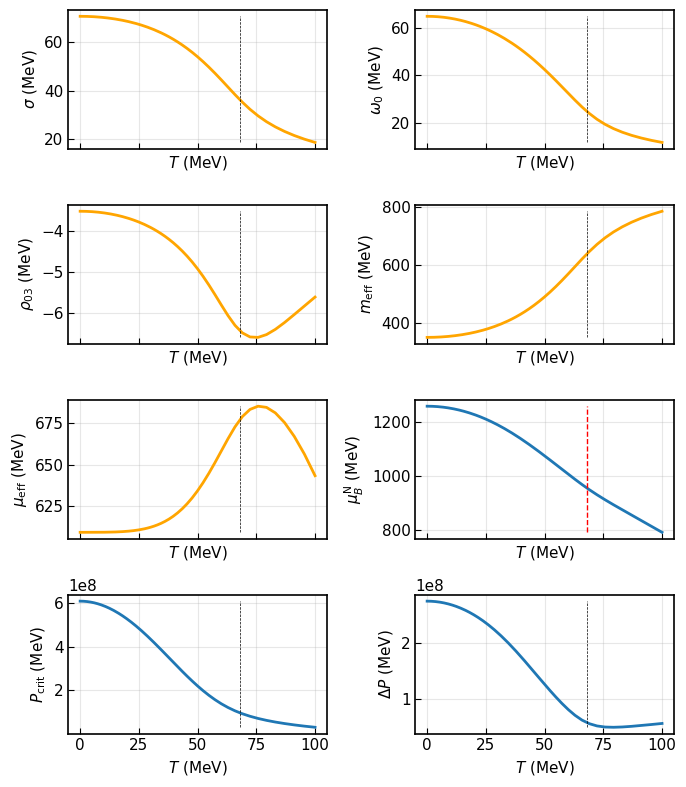

In [83]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.size": 11,
    "axes.linewidth": 1.2,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 4,
    "ytick.major.size": 4,
})

fig, axes = plt.subplots(4, 2, figsize=(7, 8), sharex=True)

#plt.title(r"$n^{\rm crit}_{T=0} = 3\,n_0$")

style = dict(lw=2.0, ms=4)

T_cc = 68

# Top-left
axes[0, 0].plot(T_list, sigma_list[:200], 'orange', **style)
axes[0, 0].plot(T_cc*np.ones(10), np.linspace(sigma_list.min(), sigma_list.max(), 10), 'k', ls='--', lw=0.5)
axes[0, 0].set_ylabel(r'$\sigma$ (MeV)')
axes[0, 0].set_xlabel(r'$T$ (MeV)')
axes[0, 0].grid(alpha=0.3)

# Top-right
axes[0, 1].plot(T_list, w0_list[:200], 'orange', **style)
axes[0, 1].plot(T_cc*np.ones(10), np.linspace(w0_list.min(), w0_list.max(), 10), 'k', ls='--', lw=0.5)
axes[0, 1].set_ylabel(r'$\omega_0$ (MeV)')
axes[0, 1].set_xlabel(r'$T$ (MeV)')
axes[0, 1].grid(alpha=0.3)

# Bottom-left
axes[1, 0].plot(T_list, r03_list[:200], 'orange', **style)
axes[1, 0].plot(T_cc*np.ones(10), np.linspace(r03_list.min(), r03_list.max(), 10), 'k', ls='--', lw=0.5)
axes[1, 0].set_ylabel(r'$\rho_{03}$ (MeV)')
axes[1, 0].set_xlabel(r'$T$ (MeV)')
axes[1, 0].grid(alpha=0.3)

# Bottom-right
axes[1, 1].plot(T_list, m_eff_list[:200], 'orange', **style)
axes[1, 1].plot(T_cc*np.ones(10), np.linspace(m_eff_list.min(), m_eff_list.max(), 10), 'k', ls='--', lw=0.5)
axes[1, 1].set_ylabel(r'$m_{\rm eff}$ (MeV)')
axes[1, 1].set_xlabel(r'$T$ (MeV)')
axes[1, 1].grid(alpha=0.3)

# Bottom-right
axes[2, 0].plot(T_list, mub_eff_list[:200], 'orange', **style)
axes[2, 0].plot(T_cc*np.ones(10), np.linspace(mub_eff_list.min(), mub_eff_list.max(), 10), 'k', ls='--', lw=0.5)
axes[2, 0].set_ylabel(r'$\mu_{\rm eff}$ (MeV)')
axes[2, 0].set_xlabel(r'$T$ (MeV)')
axes[2, 0].grid(alpha=0.3)

axes[2, 1].plot(T_list, muB_N_list[:200], **style)
axes[2, 1].plot(T_cc*np.ones(10), np.linspace(muB_N_list.min(), muB_N_list.max(), 10), 'r', ls='--', lw=1.0)
#axes[2, 1].plot(T_list, muB_N_list[:200] - muB_Q_list[:200], **style)
#axes[2, 1].plot(T_cc*np.ones(10), np.linspace((muB_N_list - muB_Q_list).min(), (muB_N_list - muB_Q_list).max(), 10), 'r', ls='--', lw=1.0)
axes[2, 1].set_ylabel(r'$\mu_B^{\rm N}$ (MeV)')
axes[2, 1].set_xlabel(r'$T$ (MeV)')
axes[2, 1].grid(alpha=0.3)

axes[3, 0].plot(T_list, P_crit_list[:200], **style)
axes[3, 0].plot(T_cc*np.ones(10), np.linspace(P_crit_list.min(), P_crit_list.max(), 10), 'k', ls='--', lw=0.5)
axes[3, 0].set_ylabel(r'$P_{\rm crit}$ (MeV)')
axes[3, 0].set_xlabel(r'$T$ (MeV)')
axes[3, 0].grid(alpha=0.3)

axes[3, 1].plot(T_list, DelP_list[:200], **style)
axes[3, 1].plot(T_cc*np.ones(10), np.linspace(DelP_list.min(), DelP_list.max(), 10), 'k', ls='--', lw=0.5)
axes[3, 1].set_ylabel(r'$\Delta P$ (MeV)')
axes[3, 1].set_xlabel(r'$T$ (MeV)')
axes[3, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

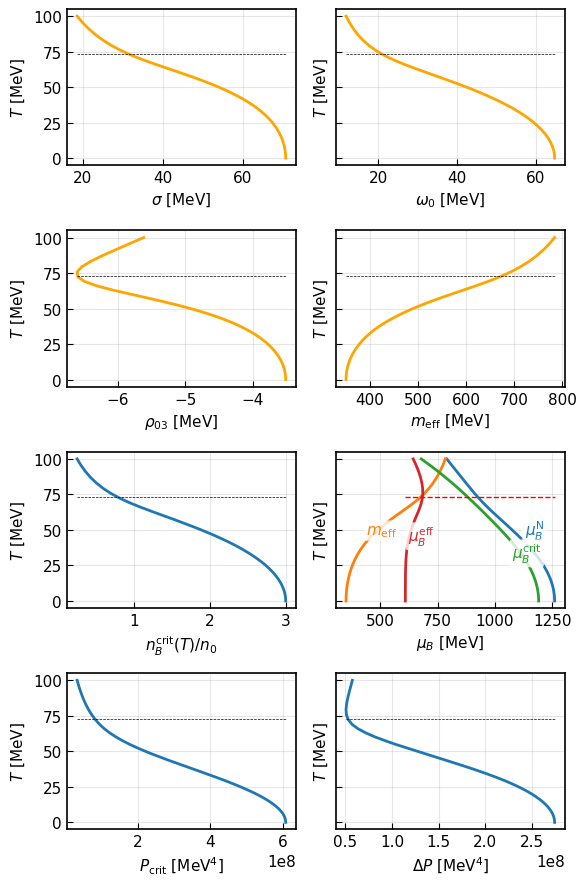

In [125]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.size": 11,
    "axes.linewidth": 1.2,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 4,
    "ytick.major.size": 4,
})

fig, axes = plt.subplots(4, 2, figsize=(6, 9), sharey=True)

style = dict(lw=2.0, ms=4)
T_cc = 73

# --- Row 1 ---
axes[0, 0].plot(sigma_list[:200], T_list, 'orange', **style)
axes[0, 0].plot(
    np.linspace(sigma_list.min(), sigma_list.max(), 10),
    T_cc * np.ones(10),
    'k', ls='--', lw=0.5
)
axes[0, 0].set_xlabel(r'$\sigma$ [MeV]')
axes[0, 0].set_ylabel(r'$T$ [MeV]')
axes[0, 0].grid(alpha=0.3)

axes[0, 1].plot(w0_list[:200], T_list, 'orange', **style)
axes[0, 1].plot(
    np.linspace(w0_list.min(), w0_list.max(), 10),
    T_cc * np.ones(10),
    'k', ls='--', lw=0.5
)
axes[0, 1].set_xlabel(r'$\omega_0$ [MeV]')
axes[0, 1].set_ylabel(r'$T$ [MeV]')
axes[0, 1].grid(alpha=0.3)

# --- Row 2 ---
axes[1, 0].plot(r03_list[:200], T_list, 'orange', **style)
axes[1, 0].plot(
    np.linspace(r03_list.min(), r03_list.max(), 10),
    T_cc * np.ones(10),
    'k', ls='--', lw=0.5
)
axes[1, 0].set_xlabel(r'$\rho_{03}$ [MeV]')
axes[1, 0].set_ylabel(r'$T$ [MeV]')
axes[1, 0].grid(alpha=0.3)

axes[1, 1].plot(m_eff_list[:200], T_list, 'orange', **style)
axes[1, 1].plot(
    np.linspace(m_eff_list.min(), m_eff_list.max(), 10),
    T_cc * np.ones(10),
    'k', ls='--', lw=0.5
)
axes[1, 1].set_xlabel(r'$m_{\rm eff}$ [MeV]')
axes[1, 1].set_ylabel(r'$T$ [MeV]')
axes[1, 1].grid(alpha=0.3)

# --- Row 3 ---
axes[2, 0].plot(n_crit_T_list[:200]/n0, T_list, **style)
axes[2, 0].plot(
    np.linspace(n_crit_T_list.min()/n0, n_crit_T_list.max()/n0, 10),
    T_cc * np.ones(10),
    'k', ls='--', lw=0.5
)
axes[2, 0].set_xlabel(r'$n^{\rm crit}_B(T)/n_0$')
axes[2, 0].set_ylabel(r'$T$ [MeV]')
axes[2, 0].grid(alpha=0.3)

# plot curves
axes[2, 1].plot(muB_N_list[:200],    T_list, **style)
axes[2, 1].plot(m_eff_list[:200],    T_list, **style)
axes[2, 1].plot(muB_crit_list[:200], T_list, **style)
axes[2, 1].plot(mub_eff_list[:200],  T_list, **style)

# critical temperature line
axes[2, 1].plot(
    np.linspace(mub_eff_list.min(), muB_N_list.max(), 10),
    T_cc * np.ones(10),
    'r', ls='--', lw=1.0
)
axes[2, 1].set_xlabel(r'$\mu_B$ [MeV]')
axes[2, 1].set_ylabel(r'$T$ [MeV]')
axes[2, 1].grid(alpha=0.3)
# --- inline labels (legend replacement) ---
# --- inline labels (moved to higher T, less cramped) ---
boxprops = dict(
    boxstyle='round,pad=0.15',
    facecolor='white',
    edgecolor='none',
    alpha=0.8
)

i = 180   # higher T than before (was ~150)

axes[2, 1].text(
    muB_N_list[i], T_list[i] + 8,
    r'$\mu_B^{\rm N}$',
    fontsize=11, color='tab:blue',
    ha='left', va='center', bbox=boxprops
)

axes[2, 1].text(
    m_eff_list[i], T_list[i] + 8,
    r'$m_{\rm eff}$',
    fontsize=11, color='tab:orange',
    ha='left', va='center', bbox=boxprops
)

axes[2, 1].text(
    muB_crit_list[i], T_list[i] - 8,
    r'$\mu_B^{\rm crit}$',
    fontsize=11, color='tab:green',
    ha='left', va='center', bbox=boxprops
)

axes[2, 1].text(
    mub_eff_list[i], T_list[i] + 4,
    r'$\mu_B^{\rm eff}$',
    fontsize=11, color='tab:red',
    ha='left', va='center', bbox=boxprops
)

# --- Row 4 ---
axes[3, 0].plot(P_crit_list[:200], T_list, **style)
axes[3, 0].plot(
    np.linspace(P_crit_list.min(), P_crit_list.max(), 10),
    T_cc * np.ones(10),
    'k', ls='--', lw=0.5
)
axes[3, 0].set_xlabel(r'$P_{\rm crit}$ [MeV$^4$]')
axes[3, 0].set_ylabel(r'$T$ [MeV]')
axes[3, 0].grid(alpha=0.3)

axes[3, 1].plot(DelP_list[:200], T_list, **style)
axes[3, 1].plot(
    np.linspace(DelP_list.min(), DelP_list.max(), 10),
    T_cc * np.ones(10),
    'k', ls='--', lw=0.5
)
axes[3, 1].set_xlabel(r'$\Delta P$ [MeV$^4$]')
axes[3, 1].set_ylabel(r'$T$ [MeV]')
axes[3, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [96]:
P_crit0 = PNM_n(n_crit0, Temp=0)
muB_crit0 = fsolve(lambda x: PNM(x, Temp=0) - P_crit0, 1050)[0]
PQM_solve_for_B = lambda x: PQM(muB_crit0, muK=0, B_one_forth=x, T=0, ms=m_s) - P_crit0
B_SQM = fsolve(PQM_solve_for_B, 180)[0]

In [97]:
T1 = 1
T2 = 10
T3 = 68
T4 = 100

mu_list = np.linspace(400, 1500, 100)
PNM1_list = np.array([PNM(mu_list[i], T1) for i in range(len(mu_list))])
PNM2_list = np.array([PNM(mu_list[i], T2) for i in range(len(mu_list))])
PNM3_list = np.array([PNM(mu_list[i], T3) for i in range(len(mu_list))])
PNM4_list = np.array([PNM(mu_list[i], T4) for i in range(len(mu_list))])

PQM1_list = np.array([PQM(mu_list[i], 0, B_SQM, T1) for i in range(len(mu_list))])
PQM2_list = np.array([PQM(mu_list[i], 0, B_SQM, T2) for i in range(len(mu_list))])
PQM3_list = np.array([PQM(mu_list[i], 0, B_SQM, T3) for i in range(len(mu_list))])
PQM4_list = np.array([PQM(mu_list[i], 0, B_SQM, T4) for i in range(len(mu_list))])


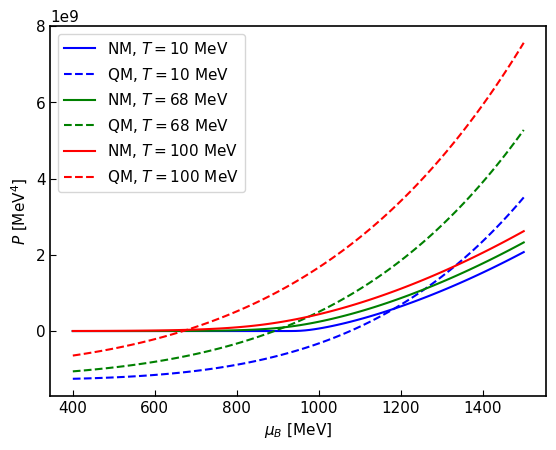

In [128]:
#plt.plot(mu_list, PNM1_list, 'purple', label=r'NM, $T=1$ MeV')
#plt.plot(mu_list, PQM1_list, 'purple', label=r'QM, $T=1$ MeV')

plt.plot(mu_list, PNM2_list, 'blue', label=r'NM, $T=10$ MeV')
plt.plot(mu_list, PQM2_list, 'blue', ls='--', label=r'QM, $T=10$ MeV')

plt.plot(mu_list, PNM3_list, 'green', label=r'NM, $T=68$ MeV')
plt.plot(mu_list, PQM3_list, 'green', ls='--', label=r'QM, $T=68$ MeV')

plt.plot(mu_list, PNM4_list, 'red', label=r'NM, $T=100$ MeV')
plt.plot(mu_list, PQM4_list, 'red', ls='--', label=r'QM, $T=100$ MeV')

plt.legend()
plt.xlabel(r'$\mu_B$ [MeV]')
plt.ylabel(r'$P$ [MeV$^4$]')
plt.savefig('NM_QM_pressure_of_muB.pdf')

/var/folders/zx/mchmm24s5sj4l19_jxvlkj380000gn/T/ipykernel_95991/238450409.py:1: RuntimeWarning: divide by zero encountered in scalar power
  f = lambda T: T**(-2) * T**(1/3) * (100 + T**2)
/var/folders/zx/mchmm24s5sj4l19_jxvlkj380000gn/T/ipykernel_95991/238450409.py:1: RuntimeWarning: invalid value encountered in scalar multiply
  f = lambda T: T**(-2) * T**(1/3) * (100 + T**2)


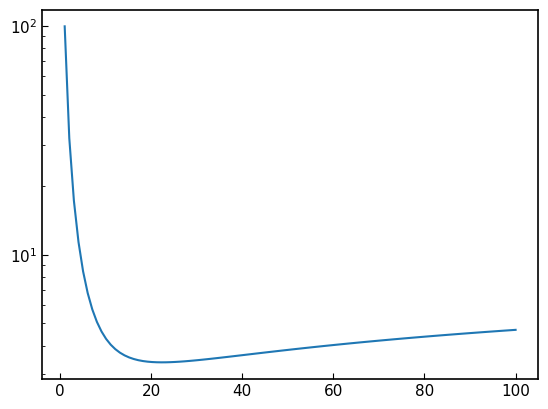

In [130]:
f = lambda T: T**(-2) * T**(1/3) * (100 + T**2)

TTT_list = np.linspace(0, 100, 100)
plt.plot(TTT_list, [f(te) for te in TTT_list])
plt.yscale('log')

* use new notation of $\bar{N}$, and things, and define new command... in the paper
* truncate the $z(t)$ when two boundary hits
* do comparasion of analytical solution v.s. numerical solution of $z(t)$, do $t_{\rm eq}$ v.s. $z_0$